# ChannelTokenFormer на PAMAP2

Ноутбук продолжает `hw01`: тот же корпус (`monster-monash/PAMAP2`), тот же fold, та же нормализация.
Задача — классификация активности (12 классов), вход `[N, 52, 100]`.

**Что реализовано**
- `ChannelTokenFormer` (CTF): частотное патчирование по каналам, канальные токены, единое masked-attention, случайное скрытие патчей при обучении.
- Базовые модели: обычный Transformer по временным шагам и channel-independent модель.
- Абляции CTF: без межканального внимания, фиксированный патч, без скрытия патчей.
- Оценка при блочных пропусках на тесте (`MISSING_RATIOS`), параметры, время обучения, latency.
- Карта межканального внимания для анализа.

В PAMAP2 все каналы изначально имеют одинаковую частоту. Асинхронность из статьи имитируется (`ASYNC=True`): плавные каналы прореживаются в 2 или 4 раза. Для классических моделей недостающие точки восстанавливаются линейной интерполяцией, CTF работает только с реально наблюдаемыми значениями.

In [1]:
%pip -q install "huggingface-hub>=1.23.0,<2.0" scikit-learn

import gc, math, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from huggingface_hub import hf_hub_download
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Устройство: cuda
GPU: Tesla T4


## 1. Конфигурация

In [12]:
# ---------------- данные ----------------
REPO_ID = "monster-monash/PAMAP2"
FOLD = 0                 # 0..4, как в hw01
TRAIN_SUBSET = None      # например 8000, чтобы быстро отладить пайплайн

# ---------------- эксперимент ----------------
SEEDS = [42, 43, 44]     # для финальных чисел лучше 5 seed, как в hw01
EPOCHS = 7
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 1e-2
USE_AMP = True           # bf16 (или fp16) на GPU

# ---------------- архитектура Transformer-моделей ----------------
D_MODEL = 64
N_HEADS = 4
N_LAYERS = 2             # >=2: на первом слое канальные токены ещё не несут информации о входе
FF_MULT = 2
DROPOUT = 0.1
D_RED = 16               # размерность каждого канального токена перед классификатором

# ---------------- ChannelTokenFormer ----------------
N_CHANNEL_TOKENS = 1     # m: число канальных токенов на канал (в статье 1..3)
PATCH_DROP = 0.4         # доля случайно скрываемых патчей при обучении (как в статье)
HEAD = "flatten"         # "flatten": токены всех каналов -> MLP; "mean": среднее по каналам

# ---------------- асинхронная дискретизация ----------------
ASYNC = True             # False: все каналы с периодом 1 (классический режим)
PERIOD_LEVELS = (1, 2, 4)

# ---------------- патчирование ----------------
P_MIN, P_MAX = 4, 25     # границы длины патча (в отсчётах канала)
BASE_PATCH = 10          # fallback: патч ~ BASE_PATCH шагов физического времени
PEAK_RATIO = 3.0         # пик FFT должен быть > PEAK_RATIO * медиана спектра
FIXED_PATCH = 10         # для абляции CTF с фиксированным размером патча

# ---------------- пропуски на тесте ----------------
MISSING_RATIOS = [0.0, 0.25, 0.5]   # доля скрытых патчей в каждом канале
BLOCK_PATCHES = 2                   # длина блока в патчах (подряд скрытые участки)

# ---------------- какие модели запускать ----------------
MODELS_TO_RUN = [
    "Transformer (time tokens)",
    "CTF (full)",
    "CTF w/o cross-channel",
    "CTF fixed patch",
    "CTF w/o patch masking",
]


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

## 2. Данные PAMAP2 (из hw01)

In [3]:
X_path = hf_hub_download(repo_id=REPO_ID, filename="PAMAP2_X.npy", repo_type="dataset")
y_path = hf_hub_download(repo_id=REPO_ID, filename="PAMAP2_y.npy", repo_type="dataset")
fold_path = hf_hub_download(repo_id=REPO_ID, filename=f"test_indices_fold_{FOLD}.txt", repo_type="dataset")
print("Файлы загружены")

PAMAP2_X.npy: reconstructing file:   0%|          |  0.00B / 1.62GB            

PAMAP2_X.npy: downloading bytes:           |  0.00B            

PAMAP2_y.npy: reconstructing file:   0%|          |  0.00B /  311kB            

PAMAP2_y.npy: downloading bytes:           |  0.00B            

test_indices_fold_0.txt:   0%|          | 0.00/59.4k [00:00<?, ?B/s]

Файлы загружены


In [4]:
X_mmap = np.load(X_path, mmap_mode="r")
y_raw = np.asarray(np.load(y_path)).reshape(-1)
test_idx = np.asarray(np.loadtxt(fold_path, dtype=np.int64)).reshape(-1)

assert X_mmap.ndim == 3 and X_mmap.shape[0] == len(y_raw)

is_train = np.ones(len(y_raw), dtype=bool)
is_train[test_idx] = False
train_idx = np.flatnonzero(is_train)

if TRAIN_SUBSET is not None:
    rng = np.random.RandomState(0)
    train_idx = np.sort(rng.choice(train_idx, size=min(TRAIN_SUBSET, len(train_idx)), replace=False))

X_train = np.asarray(X_mmap[train_idx], dtype=np.float32)
X_test = np.asarray(X_mmap[test_idx], dtype=np.float32)

encoder = LabelEncoder().fit(y_raw)
y_train = encoder.transform(y_raw[train_idx]).astype(np.int64)
y_test = encoder.transform(y_raw[test_idx]).astype(np.int64)

print("Train:", X_train.shape, "Test:", X_test.shape)
del X_mmap, y_raw, is_train
gc.collect()

Train: (28961, 52, 100) Test: (9895, 52, 100)


112

In [5]:
# Нормализация по train-статистикам (как в hw01); NaN/inf заменяются средним канала.
n_channels, seq_len = X_train.shape[1], X_train.shape[2]
channel_mean = np.zeros((1, n_channels, 1), dtype=np.float32)
channel_std = np.ones((1, n_channels, 1), dtype=np.float32)

for ch in range(n_channels):
    train_ch = X_train[:, ch, :]
    valid = np.isfinite(train_ch)
    if valid.any():
        mean = train_ch[valid].mean(dtype=np.float64)
        std = train_ch[valid].std(dtype=np.float64)
    else:
        mean, std = 0.0, 1.0
    if std < 1e-6 or not np.isfinite(std):
        std = 1.0
    train_ch[~valid] = mean
    test_ch = X_test[:, ch, :]
    test_ch[~np.isfinite(test_ch)] = mean
    channel_mean[0, ch, 0], channel_std[0, ch, 0] = mean, std

X_train -= channel_mean; X_train /= channel_std
X_test -= channel_mean;  X_test /= channel_std

n_classes = len(encoder.classes_)
L = seq_len
print(f"Каналов: {n_channels}, длина: {L}, классов: {n_classes}")

# Все данные кладём на устройство целиком (~0.8 ГБ), чтобы не тратить время на DataLoader.
Xtr_dev = torch.from_numpy(X_train).to(device)
ytr_dev = torch.from_numpy(y_train).to(device)
Xte_dev = torch.from_numpy(X_test).to(device)

Каналов: 52, длина: 100, классов: 12


## 3. Периоды дискретизации и частотное патчирование

1. `assign_sampling_periods`: чем меньше в канале энергии в верхней половине спектра, тем реже его можно прореживать (периоды 4 / 2 / 1).
2. Для каждого канала по усреднённому FFT-спектру ищется доминирующий период, он определяет длину патча. Если выраженного пика нет, используется sampling-aware fallback (патч покрывает ~`BASE_PATCH` шагов времени).
3. Длина патча подгоняется к ближайшему делителю длины канала, чтобы не терять точки.

In [6]:
def assign_sampling_periods(X, levels=(1, 2, 4), seed=0):
    rng = np.random.RandomState(seed)
    sub = X[rng.choice(len(X), min(len(X), 2000), replace=False)]
    power = (np.abs(np.fft.rfft(sub, axis=-1)) ** 2)[..., 1:].mean(0)       # [C, F-1]
    hf_ratio = power[:, power.shape[1] // 2:].sum(-1) / (power.sum(-1) + 1e-12)
    order = np.argsort(hf_ratio)                                             # от самых плавных
    periods = np.ones(X.shape[1], dtype=np.int64)
    for group, s in zip(np.array_split(order, len(levels)), levels[::-1]):
        periods[group] = s                                                   # плавные -> большой период
    return periods, hf_ratio


def snap_to_divisor(p, length, p_lo, p_hi):
    cands = [d for d in range(p_lo, p_hi + 1) if length % d == 0]
    return p if not cands else min(cands, key=lambda d: (abs(d - p), d))


class PatchConfig:
    # s: период (в шагах finest-сетки), p: длина патча в отсчётах канала, K: число патчей
    def __init__(self, s, p, how, L):
        self.s, self.p, self.how, self.L = np.asarray(s), np.asarray(p), list(how), L
        self.Li = -(-L // self.s)                    # ceil(L / s)
        self.K = self.Li // self.p
        self.C = len(self.s)

    def obs_mask(self):
        t = np.arange(self.L)[None, :]
        return torch.from_numpy((t % self.s[:, None]) == 0)    # [C, L] True = канал наблюдается


def build_patch_config(X, periods, L, mode="fft"):
    rng = np.random.RandomState(0)
    sub = X[rng.choice(len(X), min(len(X), 2000), replace=False)]
    ps, hows = [], []
    for i, s in enumerate(periods):
        s = int(s)
        Li = -(-L // s)
        p_hi = max(2, min(P_MAX, Li // 3))
        p_lo = min(P_MIN, p_hi)
        if mode == "fixed":
            ps.append(FIXED_PATCH); hows.append("fixed"); continue
        x = sub[:, i, ::s][:, :Li]
        amp = np.abs(np.fft.rfft(x - x.mean(-1, keepdims=True), axis=-1)).mean(0)
        amp[0] = 0.0
        kmax = max(1, Li // p_lo)
        window = amp[1:kmax + 1]
        base = np.median(amp[1:]) + 1e-12
        if len(window) and window.max() >= PEAK_RATIO * base:
            k = int(window.argmax()) + 1
            p = int(np.clip(round(Li / k), p_lo, p_hi)); how = "fft"
        else:
            p = int(np.clip(BASE_PATCH // s, p_lo, p_hi)); how = "fallback"
        ps.append(snap_to_divisor(p, Li, p_lo, p_hi)); hows.append(how)
    return PatchConfig(periods, ps, hows, L)


if ASYNC:
    periods, hf_ratio = assign_sampling_periods(X_train, PERIOD_LEVELS)
else:
    periods, hf_ratio = np.ones(n_channels, dtype=np.int64), np.zeros(n_channels)

cfg_dyn = build_patch_config(X_train, periods, L, mode="fft")      # частотное патчирование
cfg_fix = build_patch_config(X_train, periods, L, mode="fixed")    # абляция: один размер патча

summary = pd.DataFrame({"период s": cfg_dyn.s, "отсчётов L_i": cfg_dyn.Li, "патч p": cfg_dyn.p,
                        "патчей K": cfg_dyn.K, "способ": cfg_dyn.how, "HF-доля": hf_ratio.round(3)})
print("Всего локальных токенов у CTF (dynamic):", int(cfg_dyn.K.sum()),
      "| у fixed:", int(cfg_fix.K.sum()))
print("Периоды:", pd.Series(cfg_dyn.s).value_counts().sort_index().to_dict(),
      "| длины патчей:", pd.Series(cfg_dyn.p).value_counts().sort_index().to_dict())
display(summary.head(12))

Всего локальных токенов у CTF (dynamic): 249 | у fixed: 291
Периоды: {1: 17, 2: 17, 4: 18} | длины патчей: {5: 18, 10: 18, 25: 16}


,период s,отсчётов L_i,патч p,патчей K,способ,HF-доля
0,4,25,5,5,fft,0.010
1,2,50,10,5,fft,0.016
2,2,50,10,5,fft,0.018
3,1,100,25,4,fft,0.037
4,1,100,25,4,fft,0.060
5,4,25,5,5,fft,0.009
6,2,50,10,5,fft,0.017
7,1,100,25,4,fft,0.030
8,4,25,5,5,fft,0.009
9,4,25,5,5,fft,0.004


## 4. Блочные пропуски и линейная интерполяция

`sample_block_missing` скрывает подряд идущие блоки по `BLOCK_PATCHES` патчей в каждом канале. Одна и та же маска (с фиксированным seed) подаётся всем моделям.
`fill_linear` — линейная интерполяция по наблюдаемым точкам для классических моделей (учитывает и асинхронность, и пропуски).

In [7]:
def sample_block_missing(B, ratio, cfg, device="cpu", generator=None, block_patches=2):
    # Возвращает bool [B, C, L]: True = значение пропущено.
    # Сетка блоков задаётся патчами CTF, ratio ~ ожидаемая доля скрытых патчей.
    miss = torch.zeros(B, cfg.C, cfg.L, dtype=torch.bool, device=device)
    if ratio <= 0:
        return miss
    b = block_patches
    q = 1.0 - (1.0 - ratio) ** (1.0 / b)          # вероятность старта блока на позиции
    for i in range(cfg.C):
        K = int(cfg.K[i]); span = int(cfg.p[i] * cfg.s[i])    # шагов finest-сетки на патч
        starts = (torch.rand(B, K, device=device, generator=generator) < q).float().unsqueeze(1)
        covered = F.max_pool1d(F.pad(starts, (b - 1, 0)), kernel_size=b, stride=1)[:, 0] > 0
        miss[:, i, :K * span] = covered.repeat_interleave(span, dim=1)
    return miss


def fill_linear(x, valid):
    # x, valid: [B, C, L]. Линейная интерполяция между валидными точками,
    # на краях - заполнение ближайшим значением, если валидных точек нет - 0.
    B, C, Lx = x.shape
    idx = torch.arange(Lx, device=x.device).view(1, 1, Lx).expand(B, C, Lx)
    prev = torch.where(valid, idx, torch.full_like(idx, -1)).cummax(-1).values
    nxt = torch.where(valid, idx, torch.full_like(idx, 2 * Lx)).flip(-1).cummin(-1).values.flip(-1)
    has_p, has_n = prev >= 0, nxt < Lx
    prev_c, nxt_c = prev.clamp(min=0), nxt.clamp(max=Lx - 1)
    xp, xn = x.gather(-1, prev_c), x.gather(-1, nxt_c)
    w = (idx - prev_c).to(x.dtype) / (nxt_c - prev_c).clamp(min=1).to(x.dtype)
    out = torch.where(has_p & has_n, xp + (xn - xp) * w,
                      torch.where(has_p, xp, torch.where(has_n, xn, torch.zeros_like(x))))
    return torch.where(valid, x, out)


# Фиксированные тестовые маски (одинаковые для всех моделей и seed)
test_miss = {}
for r in MISSING_RATIOS:
    if r <= 0:
        test_miss[r] = None
        continue
    g = torch.Generator().manual_seed(1234 + int(r * 1000))
    test_miss[r] = sample_block_missing(len(Xte_dev), r, cfg_dyn, "cpu", g, BLOCK_PATCHES).to(device)
    print(f"ratio={r}: доля скрытых точек = {test_miss[r].float().mean().item():.3f}")

ratio=0.25: доля скрытых точек = 0.226
ratio=0.5: доля скрытых точек = 0.456


## 5. Архитектура ChannelTokenFormer

Токены: для канала `i` — `K_i` локальных токенов (патчи) и `m` канальных токенов. Маска внимания (True = можно смотреть):
- локальный токен видит только локальные токены своего канала;
- канальный токен читает локальные токены своего канала и канальные токены **других** каналов (на себя и на свои канальные токены не смотрит);
- локальные токены канальные не видят (read-only).

Патчи, скрытые при обучении (Bernoulli) или полностью пропущенные на тесте, исключаются из ключей внимания. Позиция патча кодируется синусоидой от реального времени его центра, поэтому каналы с разной частотой выровнены по времени. Классификация идёт только по канальным токенам.

In [8]:
def sincos_embed(t, d):
    # t: [...] время в шагах finest-сетки; возвращает [..., d]
    half = d // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, dtype=torch.float32) / half)
    ang = t.float().unsqueeze(-1) * freqs
    return torch.cat([ang.sin(), ang.cos()], dim=-1)


class AttnBlock(nn.Module):
    # Pre-LN блок: x + MHA(LN(x)), x + FFN(LN(x)); внимание принимает булеву маску [B,1,T,T] (True = можно)
    def __init__(self, d, heads, ff_mult, dropout):
        super().__init__()
        self.h, self.dp = heads, dropout
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.o = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, d * ff_mult), nn.GELU(), nn.Dropout(dropout),
                                nn.Linear(d * ff_mult, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, attn_mask=None):
        B, T, D = x.shape
        q, k, v = self.qkv(self.n1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                           dropout_p=self.dp if self.training else 0.0)
        x = x + self.drop(self.o(a.transpose(1, 2).reshape(B, T, D)))
        return x + self.drop(self.ff(self.n2(x)))


class ClassifierHead(nn.Module):
    def __init__(self, n_tokens, d, d_red, num_classes, mode, dropout):
        super().__init__()
        self.mode = mode
        self.norm = nn.LayerNorm(d)
        if mode == "flatten":
            self.reduce = nn.Linear(d, d_red)
            self.mlp = nn.Sequential(nn.Dropout(dropout), nn.Linear(n_tokens * d_red, 128),
                                     nn.GELU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
        else:
            self.mlp = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, num_classes))

    def forward(self, tok):                       # tok: [B, n_tokens, d]
        tok = self.norm(tok)
        if self.mode == "flatten":
            return self.mlp(self.reduce(tok).flatten(1))
        return self.mlp(tok.mean(1))


class ChannelTokenFormer(nn.Module):
    def __init__(self, cfg, num_classes, d_model=64, n_heads=4, n_layers=2, n_ch_tokens=1,
                 ff_mult=2, dropout=0.1, patch_drop=0.4, cross_channel=True,
                 use_patch_masking=True, head="flatten", d_red=16):
        super().__init__()
        self.C, self.m, self.d = cfg.C, n_ch_tokens, d_model
        self.patch_drop, self.cross_channel = patch_drop, cross_channel
        self.use_patch_masking = use_patch_masking
        self.register_buffer("obs_mask", cfg.obs_mask())

        # --- группы каналов с одинаковыми (p, K): их патчи эмбеддятся одним батчем общим Linear(p -> d)
        groups = {}
        for i in range(cfg.C):
            groups.setdefault((int(cfg.p[i]), int(cfg.K[i])), []).append(i)
        self.group_keys, self.group_chans = list(groups), list(groups.values())
        self.proj = nn.ModuleDict({str(p): nn.Linear(p, d_model) for p in {k[0] for k in groups}})
        for gi, ((p, K), chans) in enumerate(zip(self.group_keys, self.group_chans)):
            s = torch.as_tensor(cfg.s[chans], dtype=torch.long)
            t_idx = torch.arange(K * p).unsqueeze(0) * s.unsqueeze(1)             # [n_g, K*p] шаги finest-сетки
            centers = (torch.arange(K).float() + 0.5).unsqueeze(0) * (p * s).float().unsqueeze(1)
            self.register_buffer(f"g{gi}_chan", torch.as_tensor(chans, dtype=torch.long))
            self.register_buffer(f"g{gi}_t", t_idx)
            self.register_buffer(f"g{gi}_pos", sincos_embed(centers, d_model))    # [n_g, K, d]

        self.ch_emb = nn.Parameter(torch.randn(cfg.C, d_model) * 0.02)
        self.ch_tokens = nn.Parameter(torch.randn(cfg.C, n_ch_tokens, d_model) * 0.02)

        # --- раскладка токенов: [loc_1..loc_K1, ch_1..ch_m, loc_1..., ...]
        tok_ch, is_ch, ch_pos, pos = [], [], [], 0
        for i in range(cfg.C):
            K = int(cfg.K[i])
            tok_ch += [i] * (K + n_ch_tokens); is_ch += [False] * K + [True] * n_ch_tokens
            ch_pos += list(range(pos + K, pos + K + n_ch_tokens)); pos += K + n_ch_tokens
        tok_ch, is_ch = torch.tensor(tok_ch), torch.tensor(is_ch)
        same = tok_ch[:, None] == tok_ch[None, :]
        q_loc, k_loc = ~is_ch[:, None], ~is_ch[None, :]
        allow = q_loc & k_loc & same                          # локальные -> локальные своего канала
        allow |= is_ch[:, None] & k_loc & same                # канальный токен читает свой канал
        if cross_channel:
            allow |= is_ch[:, None] & is_ch[None, :] & ~same  # и канальные токены других каналов
        self.T = len(tok_ch)
        self.register_buffer("static_allow", allow, persistent=False)   # не попадает в state_dict
        self.register_buffer("ch_pos", torch.tensor(ch_pos))
        self.register_buffer("eye", torch.eye(self.T, dtype=torch.bool), persistent=False)
        self.register_buffer("K_t", torch.as_tensor(cfg.K, dtype=torch.long), persistent=False)

        self.blocks = nn.ModuleList([AttnBlock(d_model, n_heads, ff_mult, dropout) for _ in range(n_layers)])
        self.norm_out = nn.LayerNorm(d_model)
        self.head = ClassifierHead(cfg.C * n_ch_tokens, d_model, d_red, num_classes, head, dropout)

    def forward(self, x, miss=None, return_internals=False):
        B = x.size(0)
        valid = None if miss is None else (self.obs_mask.unsqueeze(0) & ~miss)   # [B,C,L]
        xz = x if valid is None else torch.where(valid, x, torch.zeros_like(x))   # пропуски -> 0

        loc, drop = [None] * self.C, [None] * self.C
        for gi, ((p, K), chans) in enumerate(zip(self.group_keys, self.group_chans)):
            ci, t_idx = getattr(self, f"g{gi}_chan"), getattr(self, f"g{gi}_t")
            idx = t_idx.unsqueeze(0).expand(B, -1, -1)
            xg = xz[:, ci].gather(2, idx).reshape(B, len(chans), K, p)             # только реально наблюдаемые точки
            tok = self.proj[str(p)](xg) + getattr(self, f"g{gi}_pos") + self.ch_emb[ci][None, :, None, :]

            d = torch.zeros(B, len(chans), K, dtype=torch.bool, device=x.device)
            if self.use_patch_masking:
                if self.training and self.patch_drop > 0:
                    d |= torch.rand(B, len(chans), K, device=x.device) < self.patch_drop   # обучение: случайное скрытие
                if valid is not None:
                    vg = valid[:, ci].gather(2, idx).reshape(B, len(chans), K, p)
                    d |= ~vg.any(-1)                                                       # тест: полностью пропущенные патчи
            for j, c in enumerate(chans):
                loc[c], drop[c] = tok[:, j], d[:, j]

        ch_tok = (self.ch_tokens + self.ch_emb.unsqueeze(1)).unsqueeze(0).expand(B, -1, -1, -1)
        zeros_m = torch.zeros(B, self.m, dtype=torch.bool, device=x.device)
        h = torch.cat([t for c in range(self.C) for t in (loc[c], ch_tok[:, c])], dim=1)       # [B,T,d]
        dropped = torch.cat([t for c in range(self.C) for t in (drop[c], zeros_m)], dim=1)     # [B,T]

        allow = self.static_allow.unsqueeze(0) & ~dropped.unsqueeze(1)            # скрытые токены не являются ключами
        empty = ~allow.any(-1, keepdim=True)                                      # строки без ключей -> смотрят на себя
        allow = allow | (self.eye.unsqueeze(0) & empty)
        attn_mask = allow.unsqueeze(1)                                            # [B,1,T,T]

        hs = []
        for blk in self.blocks:
            hs.append(h)
            h = blk(h, attn_mask)
        h = self.norm_out(h)
        logits = self.head(h[:, self.ch_pos])                                     # решение только по канальным токенам
        if return_internals:
            return logits, {"hs": hs, "allow": allow, "out": h}
        return logits

## 6. Baseline-модели

Обе получают тот же вход `(x, miss)`, но сначала линейно интерполируют асинхронные каналы и пропуски (так сделано в статье для «регулярных» моделей).
- `TransformerBaseline`: классический Transformer, токен = один временной шаг со всеми каналами.


In [9]:
class InterpFront(nn.Module):
    def __init__(self, obs_mask):
        super().__init__()
        self.register_buffer("obs_mask", obs_mask)
        self.trivial = bool(obs_mask.all())

    def forward(self, x, miss=None):
        if self.trivial and miss is None:
            return x
        valid = self.obs_mask.unsqueeze(0) if miss is None else (self.obs_mask.unsqueeze(0) & ~miss)
        return fill_linear(x, valid.expand_as(x))


class TransformerBaseline(nn.Module):
    def __init__(self, cfg, num_classes, d_model=64, n_heads=4, n_layers=2, ff_mult=2, dropout=0.1):
        super().__init__()
        self.front = InterpFront(cfg.obs_mask())
        self.embed = nn.Linear(cfg.C, d_model)
        self.register_buffer("pos", sincos_embed(torch.arange(cfg.L), d_model))
        self.blocks = nn.ModuleList([AttnBlock(d_model, n_heads, ff_mult, dropout) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_model, num_classes))

    def forward(self, x, miss=None):
        h = self.embed(self.front(x, miss).transpose(1, 2)) + self.pos
        for blk in self.blocks:
            h = blk(h)
        return self.fc(self.norm(h).mean(1))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

## 7. Проверка корректности (sanity checks)

Токенов T = 301 | параметры CTF: 185820
CD: |Δ состояния канала 5 при возмущении канала 0| = 6.47e-03
CI: |Δ состояния канала 5 при возмущении канала 0| = 0.00e+00
Transformer: параметры 71244
Все проверки пройдены


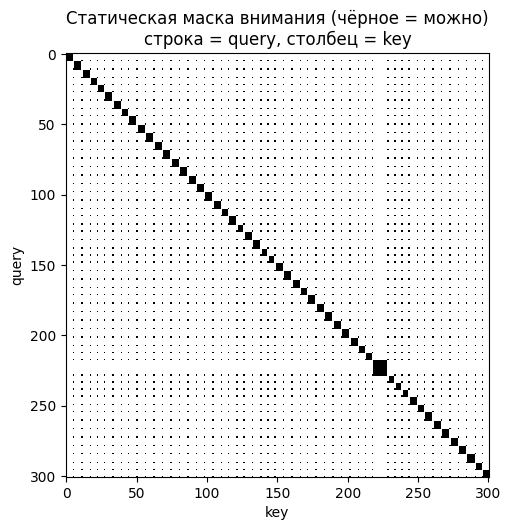

3239

In [10]:
set_seed(0)
ctf_args = dict(num_classes=n_classes, d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS,
                n_ch_tokens=N_CHANNEL_TOKENS, ff_mult=FF_MULT, dropout=DROPOUT,
                patch_drop=PATCH_DROP, head=HEAD, d_red=D_RED)

m_cd = ChannelTokenFormer(cfg_dyn, cross_channel=True, **ctf_args).to(device).eval()
m_ci = ChannelTokenFormer(cfg_dyn, cross_channel=False, **ctf_args).to(device).eval()
m_ci.load_state_dict(m_cd.state_dict())

# 1) структура маски: локальные токены не видят канальные; канальные токены не видят свой канал-токен
A = m_cd.static_allow.cpu()
is_ch_tok = torch.zeros(m_cd.T, dtype=torch.bool); is_ch_tok[m_cd.ch_pos.cpu()] = True
assert not A[~is_ch_tok][:, is_ch_tok].any(), "локальные токены не должны видеть канальные"
assert not A.diagonal()[is_ch_tok].any(), "канальный токен не должен смотреть на себя"
print("Токенов T =", m_cd.T, "| параметры CTF:", count_parameters(m_cd))

# 2) форвард с пропусками и без, нет NaN
xb = Xte_dev[:8]
mb = test_miss[[r for r in MISSING_RATIOS if r > 0][0]][:8] if any(r > 0 for r in MISSING_RATIOS) else None
with torch.no_grad():
    for name, mm in [("CD", m_cd), ("CI", m_ci)]:
        for mk in (None, mb):
            assert torch.isfinite(mm(xb, mk)).all()

# 3) изоляция каналов: возмущение канала 0 не меняет состояние канального токена канала 5 в CI-режиме
xb2 = xb.clone(); xb2[:, 0] += 3.0
with torch.no_grad():
    for name, mm in [("CD", m_cd), ("CI", m_ci)]:
        o1 = mm(xb, return_internals=True)[1]["out"][:, m_cd.ch_pos[5 * m_cd.m]]
        o2 = mm(xb2, return_internals=True)[1]["out"][:, m_cd.ch_pos[5 * m_cd.m]]
        print(f"{name}: |Δ состояния канала 5 при возмущении канала 0| = {(o1 - o2).abs().max().item():.2e}")

# 4) базовый Transformer
mm = TransformerBaseline(cfg_dyn, n_classes, D_MODEL, N_HEADS, N_LAYERS, FF_MULT, DROPOUT).to(device).eval()
with torch.no_grad():
    assert torch.isfinite(mm(xb, mb)).all()
print(f"Transformer: параметры {count_parameters(mm)}")

# 5) интерполяция: на валидных точках значения не меняются
if mb is not None:
    valid = m_cd.obs_mask.unsqueeze(0) & ~mb
    filled = fill_linear(xb, valid.expand_as(xb))
    assert torch.allclose(filled[valid.expand_as(xb)], xb[valid.expand_as(xb)])
print("Все проверки пройдены")

plt.figure(figsize=(5.5, 5.5))
plt.imshow(A.numpy(), cmap="gray_r", interpolation="nearest")
plt.title("Статическая маска внимания (чёрное = можно)\nстрока = query, столбец = key")
plt.xlabel("key"); plt.ylabel("query"); plt.show()
del m_cd, m_ci, mm
gc.collect()

## 8. Обучение и оценка

In [11]:
amp_dtype = None
if USE_AMP and device.type == "cuda":
    amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

def autocast_ctx():
    return torch.autocast(device_type=device.type, dtype=amp_dtype or torch.float32, enabled=amp_dtype is not None)


def train_model(model, seed, epochs=EPOCHS, miss_aug=0.0):
    model = model.to(device)
    N = len(Xtr_dev)
    steps_per_epoch = math.ceil(N / BATCH_SIZE)
    total, warm = epochs * steps_per_epoch, max(1, int(0.03 * epochs * steps_per_epoch))

    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler(enabled=amp_dtype == torch.float16)
    gen = torch.Generator().manual_seed(seed)
    history = []

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device); torch.cuda.synchronize(device)
    t0 = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(N, generator=gen).to(device)
        run_loss = 0.0
        for i in range(0, N, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            xb, yb = Xtr_dev[idx], ytr_dev[idx]
            miss = None
            if miss_aug > 0:      # усиленный baseline: те же блочные пропуски при обучении
                miss = sample_block_missing(len(idx), random.uniform(0, miss_aug), cfg_dyn, device,
                                            None, BLOCK_PATCHES)
            with autocast_ctx():
                loss = F.cross_entropy(model(xb, miss), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(idx)
        history.append(run_loss / N)

    if device.type == "cuda":
        torch.cuda.synchronize(device)
        peak = torch.cuda.max_memory_allocated(device) / 2 ** 20
    else:
        peak = float("nan")
    return model, history, time.perf_counter() - t0, peak


@torch.no_grad()
def predict(model, X, miss=None, bs=256):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        with autocast_ctx():
            lg = model(X[i:i + bs], None if miss is None else miss[i:i + bs])
        out.append(lg.argmax(1).cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def measure_latency(model, x_one, warmup=10, repeats=50):
    model.eval()
    for _ in range(warmup):
        model(x_one)
    if device.type == "cuda": torch.cuda.synchronize(device)
    t0 = time.perf_counter()
    for _ in range(repeats):
        model(x_one)
    if device.type == "cuda": torch.cuda.synchronize(device)
    return (time.perf_counter() - t0) * 1000 / repeats


common = dict(d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS, ff_mult=FF_MULT, dropout=DROPOUT)
ctf_common = dict(num_classes=n_classes, n_ch_tokens=N_CHANNEL_TOKENS, patch_drop=PATCH_DROP,
                  head=HEAD, d_red=D_RED, **common)

MODEL_ZOO = {
    "Transformer (time tokens)": dict(build=lambda: TransformerBaseline(cfg_dyn, n_classes, **common), aug=0.0),
    "CTF (full)": dict(build=lambda: ChannelTokenFormer(cfg_dyn, cross_channel=True, **ctf_common), aug=0.0),
    "CTF w/o cross-channel": dict(build=lambda: ChannelTokenFormer(cfg_dyn, cross_channel=False, **ctf_common), aug=0.0),
    "CTF fixed patch": dict(build=lambda: ChannelTokenFormer(cfg_fix, cross_channel=True, **ctf_common), aug=0.0),
    "CTF w/o patch masking": dict(build=lambda: ChannelTokenFormer(cfg_dyn, cross_channel=True, use_patch_masking=False, **ctf_common), aug=0.0),
}

In [13]:
records, loss_histories, trained = [], {}, {}
x_one = Xte_dev[:1]

for name in MODELS_TO_RUN:
    print(f"\n{'=' * 70}\n{name}\n{'=' * 70}")
    for seed in SEEDS:
        set_seed(seed)
        model = MODEL_ZOO[name]["build"]()
        n_params = count_parameters(model)
        model, hist, train_s, peak_mb = train_model(model, seed, EPOCHS, MODEL_ZOO[name]["aug"])
        loss_histories[(name, seed)] = hist
        latency = measure_latency(model, x_one)

        line = []
        for r in MISSING_RATIOS:
            pred = predict(model, Xte_dev, test_miss[r])
            acc = accuracy_score(y_test, pred)
            f1 = f1_score(y_test, pred, average="macro", zero_division=0)
            records.append(dict(model=name, seed=seed, missing=r, accuracy=acc, macro_f1=f1,
                                params=n_params, train_time_s=train_s, latency_ms=latency, peak_vram_mb=peak_mb))
            line.append(f"m={r}: acc={acc:.3f}")
        print(f"seed={seed} | " + " | ".join(line) +
              f" | params={n_params} | train={train_s:.0f}s | latency={latency:.2f}ms")
        if seed == SEEDS[0]:
            trained[name] = model            # для анализа внимания оставляем модель первого seed
        else:
            del model
        gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()

runs_df = pd.DataFrame(records)
runs_df.to_csv("ctf_pamap2_runs.csv", index=False)


Transformer (time tokens)
seed=42 | m=0.0: acc=0.780 | m=0.25: acc=0.709 | m=0.5: acc=0.625 | params=71244 | train=36s | latency=1.42ms
seed=43 | m=0.0: acc=0.752 | m=0.25: acc=0.699 | m=0.5: acc=0.608 | params=71244 | train=37s | latency=1.44ms
seed=44 | m=0.0: acc=0.687 | m=0.25: acc=0.652 | m=0.5: acc=0.587 | params=71244 | train=37s | latency=1.46ms

CTF (full)
seed=42 | m=0.0: acc=0.696 | m=0.25: acc=0.686 | m=0.5: acc=0.666 | params=185820 | train=171s | latency=2.82ms
seed=43 | m=0.0: acc=0.664 | m=0.25: acc=0.652 | m=0.5: acc=0.619 | params=185820 | train=170s | latency=3.67ms
seed=44 | m=0.0: acc=0.725 | m=0.25: acc=0.712 | m=0.5: acc=0.667 | params=185820 | train=170s | latency=2.87ms

CTF w/o cross-channel
seed=42 | m=0.0: acc=0.758 | m=0.25: acc=0.744 | m=0.5: acc=0.692 | params=185820 | train=170s | latency=2.83ms
seed=43 | m=0.0: acc=0.725 | m=0.25: acc=0.707 | m=0.5: acc=0.673 | params=185820 | train=170s | latency=3.76ms
seed=44 | m=0.0: acc=0.698 | m=0.25: acc=0.682 |

## 9. Результаты

In [14]:
agg = runs_df.groupby(["model", "missing"]).agg(
    acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
    f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std")).reset_index()

pivot = agg.pivot(index="model", columns="missing")
table = pd.DataFrame(index=[m for m in MODELS_TO_RUN if m in pivot.index])
for r in MISSING_RATIOS:
    table[f"Acc, m={r}"] = [f"{100 * pivot['acc_mean'][r][m]:.2f} ± {100 * pivot['acc_std'][r][m]:.2f}" for m in table.index]
for r in MISSING_RATIOS:
    table[f"F1, m={r}"] = [f"{100 * pivot['f1_mean'][r][m]:.2f} ± {100 * pivot['f1_std'][r][m]:.2f}" for m in table.index]
print("Качество (%) по seed: mean ± std")
display(table)

cost = runs_df.groupby("model").agg(params=("params", "first"), train_time_s=("train_time_s", "mean"),
                                    latency_ms=("latency_ms", "mean"), peak_vram_mb=("peak_vram_mb", "mean"))
display(cost.loc[table.index].round(2))

Качество (%) по seed: mean ± std


,"Acc, m=0.0","Acc, m=0.25","Acc, m=0.5","F1, m=0.0","F1, m=0.25","F1, m=0.5"
Transformer (time tokens),73.96 ± 4.79,68.69 ± 3.06,60.66 ± 1.90,72.19 ± 4.91,65.74 ± 3.31,56.87 ± 2.18
CTF (full),69.50 ± 3.07,68.33 ± 3.02,65.08 ± 2.75,67.50 ± 3.18,66.10 ± 2.98,62.33 ± 2.98
CTF w/o cross-channel,72.67 ± 3.01,71.11 ± 3.14,67.29 ± 1.90,69.95 ± 3.10,68.34 ± 3.07,64.25 ± 2.25
CTF fixed patch,72.47 ± 4.06,71.02 ± 3.41,67.50 ± 2.27,68.43 ± 4.33,66.87 ± 3.89,63.03 ± 2.81
CTF w/o patch masking,74.18 ± 6.88,70.96 ± 5.91,62.94 ± 4.98,71.17 ± 5.80,67.67 ± 5.03,59.22 ± 4.19


,params,train_time_s,latency_ms,peak_vram_mb
Transformer (time tokens),71244,36.69,1.44,1065.34
CTF (full),185820,170.37,3.12,2146.41
CTF w/o cross-channel,185820,169.73,3.19,2148.10
CTF fixed patch,183772,206.99,2.67,2499.71
CTF w/o patch masking,185820,170.38,3.32,2151.54


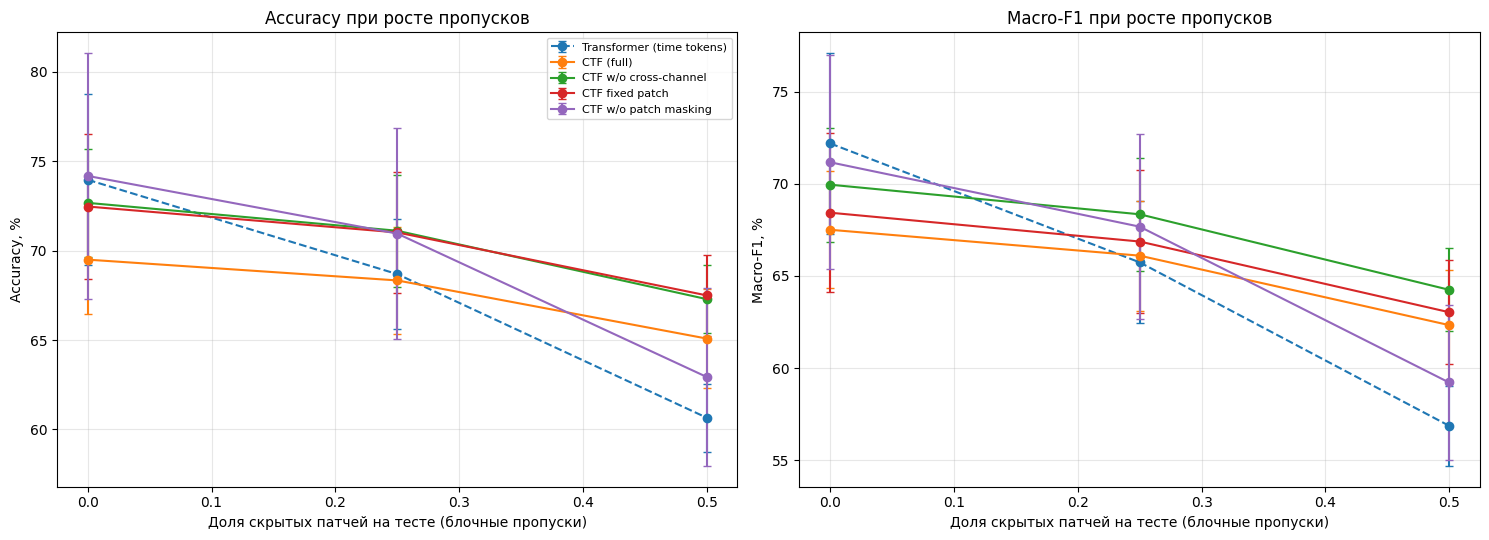

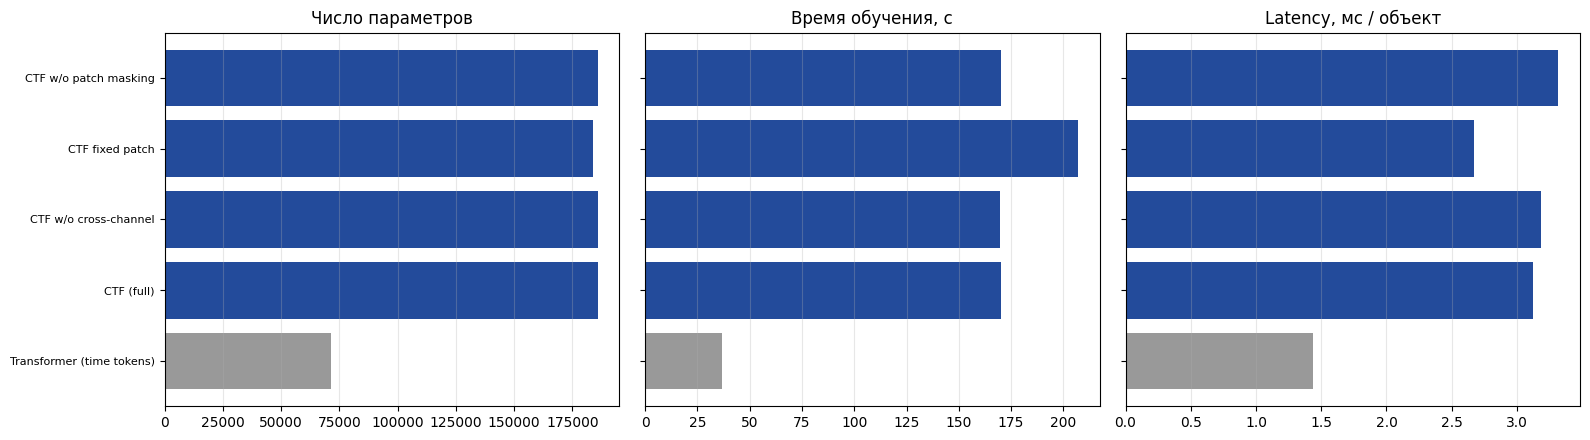

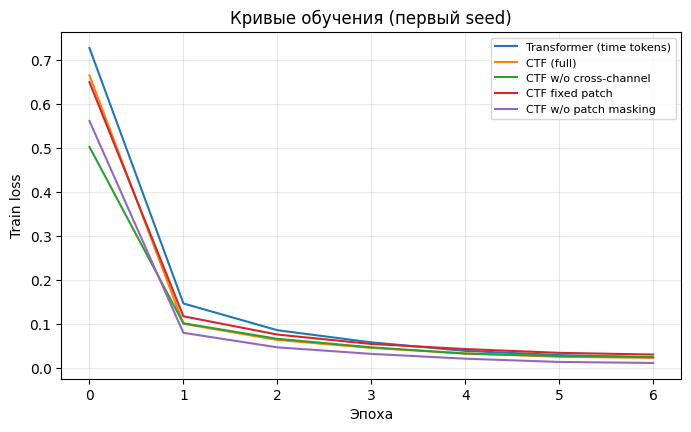

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (col, title) in zip(axes, [("accuracy", "Accuracy"), ("macro_f1", "Macro-F1")]):
    for name in table.index:
        d = runs_df[runs_df.model == name].groupby("missing")[col].agg(["mean", "std"]).fillna(0) * 100
        ls = "-" if name.startswith("CTF") else "--"
        ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, ls=ls, label=name)
    ax.set_xlabel("Доля скрытых патчей на тесте (блочные пропуски)")
    ax.set_ylabel(f"{title}, %"); ax.set_title(f"{title} при росте пропусков"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in zip(axes, ["params", "train_time_s", "latency_ms"],
                          ["Число параметров", "Время обучения, с", "Latency, мс / объект"]):
    vals = cost.loc[table.index, col]
    ax.barh(range(len(vals)), vals.values, color=["#234B9B" if n.startswith("CTF") else "#999999" for n in vals.index])
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(vals.index if col == "params" else [""] * len(vals), fontsize=8)
    ax.set_title(title); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4.5))
for (name, seed), h in loss_histories.items():
    if seed == SEEDS[0]:
        plt.plot(h, label=name)
plt.xlabel("Эпоха"); plt.ylabel("Train loss"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.title("Кривые обучения (первый seed)"); plt.show()

## 10. Абляции и вывод: когда межканальный обмен помогает

1. Все модели справились лучше чем модели из прошлой домашки, это неудивительно так как обычные сверточные хоть и очень хитрые все равно слабее трансформеров
2. Обычный трансформер показал достаточно неплохие результаты с коэфициентом скрытия 0. Скоры получились на уровне с остальными моделями, это ожидаемый результат, так как наша модель как раз придумывалась для преодоления сложностей с пропущенными участками в данных, и когда нет пропусков то и смысла нет применять нашу модель(по крайней мере идею с маскированием патчей во время трейна)
3. Когда мы подняли коэфициент скрытия до 0.25 вперед вышли модели в которых был механизм маскирования, а вот обычный трансформер и CTF без максирования просели по скорам. Это случилось потому что модели были не готовы к тому что им скроют какую-то часть данных, во время обучения они видели все данные.
4. При коэфициенте скрытия 0.5 скоры моделей без механизма маскирования упали еще сильнее, а скоры остальных просели не так сильно.
5. Так же нужно заметить что CTF с полным набором приколов из статьи показала худшие результаты чем модели с абляциями. Это получилось потому что, как мы уже говорили в прошлой домашке, данные достаточно простые, в них нет каких-то сложных зависимостей поэтому усложнение модели не дает сильного прироста. Модель пытается найти сложные зависимости в данных, которых нет, а простые пропускает. Конкретно в этой задаче плохо сработал механизм динамического выбора размера патча для каждого канала. Это связано с тем что почти у всех каналов одна частота дискретизации(только у пульсометра отличается)

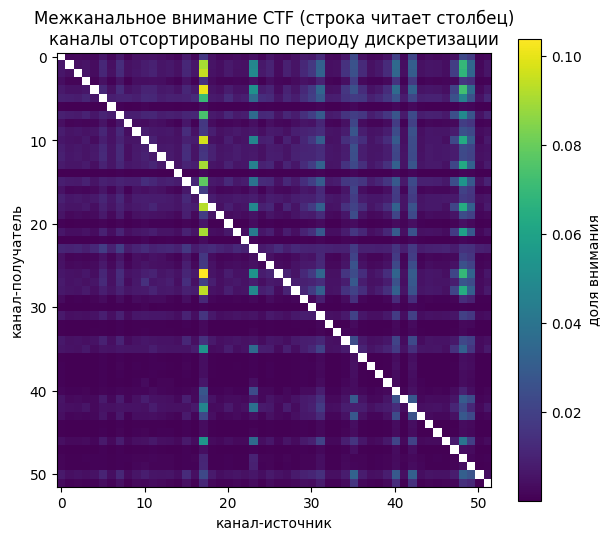

Среднее внимание, получаемое каналом, по периодам дискретизации:


,attention
1,0.2203
2,0.3669
4,0.4224


In [17]:
# Карта внимания канальных токенов (последний слой): какие каналы читают информацию друг у друга.
@torch.no_grad()
def channel_attention_map(model, X, miss=None, n=256):
    model.eval()
    xb = X[:n]
    _, info = model(xb, None if miss is None else miss[:n], return_internals=True)
    blk, h, allow = model.blocks[-1], info["hs"][-1], info["allow"]
    B, T, D = h.shape; H = blk.h
    q, k, _ = blk.qkv(blk.n1(h)).view(B, T, 3, H, D // H).permute(2, 0, 3, 1, 4)
    q = q[:, :, model.ch_pos]                                              # только строки канальных токенов
    att = (q @ k.transpose(-1, -2)) / math.sqrt(D // H)
    att = att.masked_fill(~allow[:, model.ch_pos].unsqueeze(1), float("-inf")).softmax(-1).mean((0, 1))   # [C*m, T]
    C, m = model.C, model.m
    tok_ch = torch.repeat_interleave(torch.arange(C, device=att.device),
                                     model.K_t + m)
    out = torch.zeros(C, C, device=att.device)
    out.index_add_(1, tok_ch, att.view(C, m, -1).mean(1))                  # сумма внимания по токенам канала-ключа
    return out.cpu().numpy()

if "CTF (full)" in trained:
    mdl = trained["CTF (full)"]
    att_map = channel_attention_map(mdl, Xte_dev)
    np.fill_diagonal(att_map, np.nan)                      # внимание на свои токены запрещено маской
    order = np.argsort(cfg_dyn.s, kind="stable")           # сортируем каналы по периоду дискретизации
    plt.figure(figsize=(7, 6))
    plt.imshow(att_map[np.ix_(order, order)], cmap="viridis")
    plt.colorbar(label="доля внимания")
    plt.title("Межканальное внимание CTF (строка читает столбец)\nканалы отсортированы по периоду дискретизации")
    plt.xlabel("канал-источник"); plt.ylabel("канал-получатель"); plt.show()

    # какую долю внимания получают каналы каждой группы периодов
    grp = pd.Series(np.nansum(att_map, axis=0), index=range(n_channels)).groupby(cfg_dyn.s).mean()
    print("Среднее внимание, получаемое каналом, по периодам дискретизации:")
    display(grp.round(4).to_frame("attention"))